# 02 — GloVe + BiLSTM (attention), staged tuning

Second model of the project: **GloVe 6B 100d** word vectors feeding a **bidirectional LSTM** with attention pooling.
Trained on `data/processed/train_split.json` and evaluated on `data/processed/val_split.json` (the shared stratified 85/15 split, seed 42). The unlabeled test reviews are never loaded here.

Reusable code is in `src/glove_bilstm.py` (unit-tested with `python -m pytest tests -v`). This notebook runs the experiments.

## How the final model is chosen: staged tuning

Training a BiLSTM means choosing settings the data cannot tell us directly (how to initialise the word vectors, the learning rate, how to pool, the model size, how to weight the loss). Trying every combination is too expensive, so we tune **one setting at a time, in order of expected impact, and carry each winner forward**:

```
baseline ──> Stage 1: embeddings ──> Stage 2: learning rate ──> Stage 3: pooling ──> Stage 4: hidden size ──> Stage 5: class weighting ──> FINAL model
(all defaults)   winner W1 kept        W1 + best lr = W2            W2 + best pool = W3     W3 + best size = W4       W4 + best loss = W5          W5 x 3 seeds
```

Inside a stage only that one setting changes; everything else is the current winner. So every comparison is fair, and the last stage's winner *is* the final model.

**Decision rule used at every stage (written down so the choice is defensible):**
1. Rank candidates by validation **Negative F1** (the F1 of the negative class; only ~15% of reviews are negative, so accuracy barely moves: always answering "positive" already scores ~85%).
2. Candidates within the **noise band** of the best score are treated as tied. The band is measured, not guessed: it is the spread of the baseline's Negative F1 over three seeds (Stage 0).
3. Among tied candidates, choose the **simplest** (fewest trainable parameters), then the highest PR-AUC.

**Epochs are not a tuned setting.** Each run trains for up to 15 epochs and early stopping keeps the epoch with the best validation Negative F1 (stops after 3 epochs without improvement). The training curves of the final model show why that epoch is a sensible stopping point.

**What is not tuned:** layers (1), dropout (0.4), batch size (64), reading direction (bidirectional), `MAX_LEN` (150), GloVe dimension (100). They are fixed at reasonable defaults, stated in the report.

Outputs go to `results/bilstm/` (git-ignored). Runs are cached by their exact settings, so interrupting and re-running the notebook never repeats or mixes work.

In [1]:
# ==================== SETUP ====================
import hashlib                   # short fingerprint of a run's settings (cache key)
import json                      # save/load small result files
import time                      # wall-clock timing
from pathlib import Path

import matplotlib.pyplot as plt  # stage charts, curves, confusion matrix
import numpy as np
import pandas as pd

# All model logic lives in src/glove_bilstm.py (unit-tested); the notebook only calls it.
from src.glove_bilstm import (
    BiLSTMClassifier, build_embedding_matrix, build_vocab, download_glove, encode,
    load_glove, load_split, predict_proba, set_seed, train_model,
)

SEED = 42        # fixed seed for every tuning run, so differences come from the setting, not luck
MAX_LEN = 150    # every review becomes exactly 150 tokens (words + punctuation). About 94% of training
                 # reviews fit; longer ones keep their first 150 tokens.
DEVICE = "cpu"   # CPU runs from a clean start are reproducible; the Apple GPU backend is not guaranteed to be
RESULTS = Path("results/bilstm")
for sub in ("probs", "histories"):
    (RESULTS / sub).mkdir(parents=True, exist_ok=True)   # P(positive) per validation review / per-epoch history
set_seed(SEED)

In [2]:
# ==================== DATA, VOCABULARY, EMBEDDINGS (training split only) ====================
# 1) Load the shared splits made by 00_Data_Preparation.ipynb: (list of review strings, list of 0/1 labels).
#    Example: train_texts[0] = "definitely like this boot. it does run small around the calf. ..." and train_y[0] = 1
train_texts, train_y = load_split("data/processed/train_split.json")   # 6,104 reviews: used to learn
val_texts, val_y = load_split("data/processed/val_split.json")         # 1,078 reviews: used to evaluate

# 2) Vocabulary: word -> integer id from TRAINING reviews only (using validation words would leak information).
#    Words seen fewer than 2 times are dropped and later map to <unk>.
#    Example: {"<pad>": 0, "<unk>": 1, "the": 3, "not": 30, "great": 32, ...}  -> 7,066 entries
vocab = build_vocab(train_texts, min_freq=2)

# 3) GloVe: download once (~822 MB zip; only the 100-dim file is kept) into {word: 100 numbers}.
#    Example: glove["good"] = [-0.031, 0.120, 0.539, -0.437, ...]  (400,000 words)
glove = load_glove(download_glove("data/glove"), dim=100)

# 4) Two possible starting points for the embedding layer, one row per vocabulary id:
#    "glove":  pretrained GloVe vectors (small random vector for words GloVe lacks, e.g. "it's"; zeros for <pad>)
#    "random": small random vectors for every word (no pretraining), to measure what GloVe contributes.
#    Shape (7066, 100) each. build_embedding_matrix with an empty dictionary gives the all-random matrix.
EMBEDDINGS = {
    "glove": build_embedding_matrix(vocab, glove, dim=100, seed=SEED),
    "random": build_embedding_matrix(vocab, {}, dim=100, seed=SEED),
}

# 5) Encode each review as exactly MAX_LEN ids: lowercase + split into words/punctuation, look up each token
#    (unknown -> 1), cut to 150, pad with 0.
#    Example (MAX_LEN=12): "I did not like this movie, it was bad!"
#      tokens: [i, did, not, like, this, movie, ",", it, was, bad, "!"]
#      ids:    [4, 156, 30, 38, 14, 1408, 5, 9, 22, 418, 20, 0]   <- last 0 is padding
X_train = [encode(t, vocab, MAX_LEN) for t in train_texts]
X_val = [encode(t, vocab, MAX_LEN) for t in val_texts]

# Sanity numbers for the report: GloVe coverage (the uncovered words are mostly contractions such as "it's"
# and "don't": GloVe stores them as "it" + "'s" but our tokenizer keeps the apostrophe inside the word) and
# the class balance, which should match between train and validation (~0.854 positive).
coverage = sum(w in glove for w in vocab) / len(vocab)
print(f"train {len(X_train)} | val {len(X_val)} | vocab {len(vocab)} | GloVe coverage {coverage:.1%}")
print(f"positive share  train {np.mean(train_y):.3f} | val {np.mean(val_y):.3f}")

train 6104 | val 1078 | vocab 7066 | GloVe coverage 93.9%
positive share  train 0.854 | val 0.854


In [3]:
# ==================== RUN MACHINERY (cached by exact settings) ====================
# The baseline: sensible defaults. Every stage changes ONE entry of the current winner configuration.
BASELINE = dict(
    init="glove",          # starting point of the embedding layer: "glove" (pretrained) or "random"
    freeze=True,           # True: embedding vectors stay fixed; False: they are fine-tuned during training
    hidden=128,            # LSTM state size per direction; the BiLSTM output per word is 2 x 128 = 256 numbers
    layers=1,              # stacked LSTM layers (fixed)
    dropout=0.4,           # randomly zero 40% of the review vector during training (fixed; reduces overfitting)
    pooling="attention",   # how per-word states become one review vector: attention | max | last
    bidirectional=True,    # read left-to-right and right-to-left (fixed)
    class_weighted=False,  # True: mistakes on the rare negative class cost more in the loss
    lr=1e-3,               # learning rate: size of each weight update (0.001)
    batch_size=64,         # reviews per update step (fixed)
    seed=SEED,
)

csv_path = RESULTS / "runs.csv"
RUNS = {r["key"]: r for r in pd.read_csv(csv_path).to_dict("records")} if csv_path.exists() else {}


def config_key(config):
    """Short fingerprint of the exact settings. Same settings -> same key -> the saved run is reused.
    Example: a stage-2 candidate whose settings equal the stage-1 winner is not trained a second time."""
    return hashlib.md5(json.dumps(config, sort_keys=True).encode()).hexdigest()[:8]


def get_run(config, label):
    """Return the result row for this configuration, training it only if it has not been run before."""
    key = config_key(config)
    if key not in RUNS:
        print(f"[train] {label}  (key {key})")
        set_seed(config["seed"])
        # Shapes per batch of B reviews: ids (B, L) -> embeddings (B, L, 100) -> BiLSTM (B, L, 2*hidden)
        #   -> pooled (B, 2*hidden) -> logits (B, 2). L is the longest real review in the batch (at most 150).
        model = BiLSTMClassifier(
            EMBEDDINGS[config["init"]], hidden=config["hidden"], layers=config["layers"],
            dropout=config["dropout"], pooling=config["pooling"], bidirectional=config["bidirectional"],
            freeze_embeddings=config["freeze"],
        )
        # AdamW + cross-entropy. After every epoch the model is scored on the validation set; training stops
        # after 3 epochs without a better validation Negative F1 and the best epoch's weights are restored.
        res = train_model(
            model, X_train, train_y, X_val, val_y, lr=config["lr"], batch_size=config["batch_size"],
            class_weighted=config["class_weighted"], seed=config["seed"], device=DEVICE, verbose=True,
        )
        # Keep P(positive) per validation review (PR curve, error analysis) and the per-epoch history (curves).
        np.save(RESULTS / "probs" / f"{key}.npy", predict_proba(model, X_val, device=DEVICE))
        (RESULTS / "histories" / f"{key}.json").write_text(json.dumps(res["history"]))
        m = res["metrics"]
        RUNS[key] = {
            "key": key, "config": json.dumps(config, sort_keys=True), "best_epoch": res["best_epoch"],
            "accuracy": m["accuracy"], "precision": m["precision"], "recall": m["recall"], "f1": m["f1"],
            "neg_f1": m["neg_f1"], "pr_auc": m["pr_auc"], "train_seconds": round(res["train_seconds"], 1),
            # trainable parameters only: frozen embedding vectors are not counted (fine-tuning adds ~0.7M)
            "trainable_params": sum(p.numel() for p in model.parameters() if p.requires_grad),
        }
        pd.DataFrame(RUNS.values()).to_csv(csv_path, index=False)   # save immediately: safe to interrupt
    return {**RUNS[key], "label": label}

In [4]:
# ==================== STAGE 0: HOW NOISY IS A SINGLE RUN? ====================
# The same baseline trained with 3 different seeds (different initialisation and batch order). The spread of
# its Negative F1 tells us how big a difference must be before it means anything.
# Example: if the three scores are 0.69, 0.71, 0.70, the spread is ~0.01, so a candidate that is 0.005 better
# than another is NOT really better.
baseline_rows = [get_run({**BASELINE, "seed": s}, f"baseline seed {s}") for s in (42, 43, 44)]
baseline_negf1 = [r["neg_f1"] for r in baseline_rows]
NOISE = max(float(np.std(baseline_negf1, ddof=1)), 0.01)   # sample std of 3 seeds, floored at 0.01
print(f"baseline Negative F1 over 3 seeds: {np.round(baseline_negf1, 4)}")
print(f"NOISE band = {NOISE:.4f}  (candidates closer than this to the best are treated as tied)")

[train] baseline seed 42  (key a559269f)


  epoch 1/15  train_loss 0.4195  val_loss 0.3853  val_negF1 0.0000  (16s)


  epoch 2/15  train_loss 0.3428  val_loss 0.2939  val_negF1 0.4000  (32s)


  epoch 3/15  train_loss 0.2807  val_loss 0.2687  val_negF1 0.5714  (48s)


  epoch 4/15  train_loss 0.2608  val_loss 0.2749  val_negF1 0.6061  (64s)


...

  epoch 7/15  train_loss 0.2065  val_loss 0.2287  val_negF1 0.6507  (106s)


  epoch 8/15  train_loss 0.1894  val_loss 0.2445  val_negF1 0.6183  (122s)


  epoch 9/15  train_loss 0.1667  val_loss 0.2896  val_negF1 0.6094  (136s)


  epoch 10/15  train_loss 0.1523  val_loss 0.2568  val_negF1 0.6420  (150s)


baseline Negative F1 over 3 seeds: [0.6688 0.6426 0.6507]
NOISE band = 0.0134  (candidates closer than this to the best are treated as tied)


In [5]:
# ==================== STAGED SEARCH ====================
# Each stage: (name, [(label, overrides), ...]). Candidates are listed from the setting we expect to matter most.
STAGES = [
    ("embeddings",      [("frozen GloVe", dict(init="glove", freeze=True)),
                         ("fine-tuned GloVe", dict(init="glove", freeze=False)),
                         ("random init (trained)", dict(init="random", freeze=False))]),
    ("learning rate",   [(f"lr={v:g}", dict(lr=v)) for v in (1e-4, 3e-4, 1e-3, 3e-3, 1e-2)]),
    ("pooling",         [(p, dict(pooling=p)) for p in ("attention", "max", "last")]),
    ("hidden size",     [(f"hidden={h}", dict(hidden=h)) for h in (64, 128, 256)]),
    ("class weighting", [("unweighted", dict(class_weighted=False)),
                         ("class-weighted", dict(class_weighted=True))]),
]


def pick_winner(rows, noise):
    """Decision rule: best Negative F1, then simplest model among candidates within the noise band."""
    top = max(r["neg_f1"] for r in rows)
    band = [r for r in rows if r["neg_f1"] >= top - noise]
    # simplest first (fewest trainable parameters), then highest PR-AUC
    winner = sorted(band, key=lambda r: (r["trainable_params"], -r["pr_auc"]))[0]
    return winner, band


current = dict(BASELINE)    # the winner so far; starts as the baseline
stage_log = []
for stage_name, candidates in STAGES:
    print(f"\n=== Stage: {stage_name} (all other settings = current winner) ===")
    rows = []
    for label, overrides in candidates:
        # {**current, **overrides}: copy the current winner and replace only the setting being tested.
        # Example: current = fine-tuned GloVe, overrides = {"lr": 3e-4} -> fine-tuned GloVe with lr 3e-4.
        rows.append(get_run({**current, **overrides}, label))
    winner, band = pick_winner(rows, NOISE)
    current = json.loads(winner["config"])        # carry the winner forward into the next stage
    stage_log.append(dict(stage=stage_name, rows=rows, winner=winner["label"], band=[r["label"] for r in band]))
    table = pd.DataFrame(rows)[["label", "best_epoch", "accuracy", "neg_f1", "pr_auc", "train_seconds", "trainable_params"]]
    table["tied with best"] = table["label"].isin([r["label"] for r in band])
    table["winner"] = table["label"] == winner["label"]
    display(table.round(4))
    print(f"Tied within {NOISE:.3f} of the best: {[r['label'] for r in band]}  ->  winner: {winner['label']}")

FINAL_CONFIG = current
print("\nFinal configuration:", {k: v for k, v in FINAL_CONFIG.items() if k != "seed"})

# Save one tidy table of all stages for the report.
pd.concat([pd.DataFrame(s["rows"]).assign(stage=s["stage"], winner=lambda d, w=s["winner"]: d["label"] == w)
           for s in stage_log]).to_csv(RESULTS / "stages.csv", index=False)


=== Stage: embeddings (all other settings = current winner) ===
[train] fine-tuned GloVe  (key e95c3120)


  epoch 1/15  train_loss 0.4138  val_loss 0.3601  val_negF1 0.0000  (14s)


  epoch 2/15  train_loss 0.2954  val_loss 0.2407  val_negF1 0.5920  (28s)


  epoch 3/15  train_loss 0.2022  val_loss 0.2537  val_negF1 0.6592  (43s)


  epoch 4/15  train_loss 0.1575  val_loss 0.2107  val_negF1 0.7070  (58s)


...

  epoch 3/15  train_loss 0.0887  val_loss 0.3254  val_negF1 0.6581  (57s)


  epoch 4/15  train_loss 0.0493  val_loss 0.4340  val_negF1 0.6409  (75s)


  epoch 5/15  train_loss 0.0230  val_loss 0.5033  val_negF1 0.6481  (91s)


,label,best_epoch,accuracy,neg_f1,pr_auc,train_seconds,trainable_params,tied with best,winner
0,unweighted,1,0.9230,0.7365,0.9877,58.5,942891,True,True
1,class-weighted,2,0.9045,0.6771,0.9795,90.9,942891,False,False


Tied within 0.013 of the best: ['unweighted']  ->  winner: unweighted

Final configuration: {'batch_size': 64, 'bidirectional': True, 'class_weighted': False, 'dropout': 0.4, 'freeze': False, 'hidden': 128, 'init': 'glove', 'layers': 1, 'lr': 0.01, 'pooling': 'attention'}


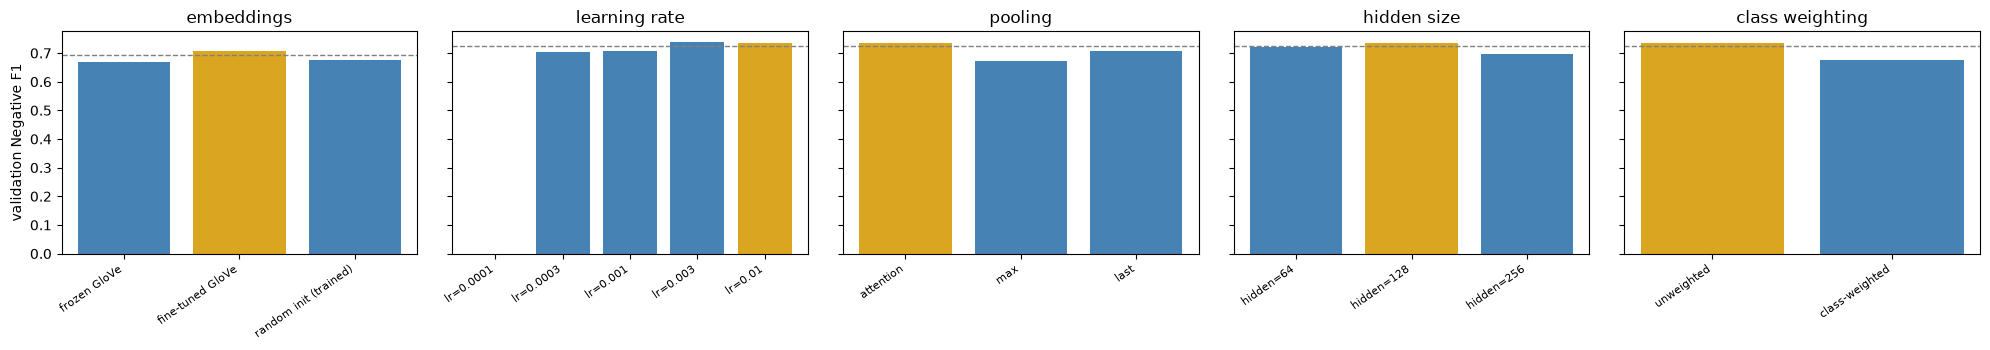

In [6]:
# ==================== STAGE CHARTS: WHICH SETTING MATTERED? ====================
# One panel per stage: bars = validation Negative F1 of each candidate, dashed line = the noise band below the
# best candidate (bars above the line are tied with the best). Gold bar = the chosen winner.
fig, axes = plt.subplots(1, len(stage_log), figsize=(4 * len(stage_log), 3.6), sharey=True)
for ax, s in zip(axes, stage_log):
    labels = [r["label"] for r in s["rows"]]
    scores = [r["neg_f1"] for r in s["rows"]]
    ax.bar(range(len(scores)), scores, color=["goldenrod" if l == s["winner"] else "steelblue" for l in labels])
    ax.axhline(max(scores) - NOISE, color="gray", ls="--", lw=1)
    ax.set_xticks(range(len(scores))); ax.set_xticklabels(labels, rotation=35, ha="right", fontsize=8)
    ax.set_title(s["stage"])
axes[0].set_ylabel("validation Negative F1")
fig.tight_layout(); fig.savefig(RESULTS / "stages.png", dpi=150); plt.show()

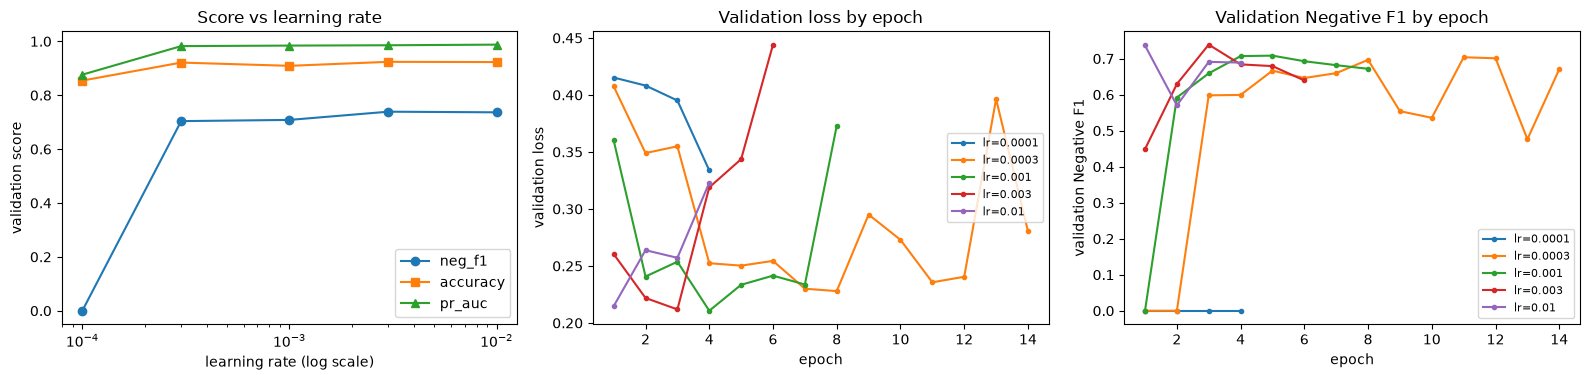

Chosen learning rate: lr=0.01   (tied within the noise band: ['lr=0.003', 'lr=0.01'])


In [7]:
# ==================== LEARNING RATE: SCORE AND TRAINING CURVES ====================
# The learning rate sets the size of each weight update. Too small: learning is slow, so the score is still
# rising when early stopping gives up. Too large: updates overshoot, the loss bounces, and the best epoch comes
# very early. These plots show that for the Stage 2 candidates (all other settings = the Stage 1 winner).
lr_stage = next(s for s in stage_log if s["stage"] == "learning rate")
lr_rows = sorted(lr_stage["rows"], key=lambda r: json.loads(r["config"])["lr"])
lrs = [json.loads(r["config"])["lr"] for r in lr_rows]

fig, ax = plt.subplots(1, 3, figsize=(16, 3.9))
# (1) Final validation score against learning rate: the main picture for choosing the rate.
for metric, marker in (("neg_f1", "o-"), ("accuracy", "s-"), ("pr_auc", "^-")):
    ax[0].plot(lrs, [r[metric] for r in lr_rows], marker, label=metric)
ax[0].set_xscale("log"); ax[0].legend()
ax[0].set(xlabel="learning rate (log scale)", ylabel="validation score", title="Score vs learning rate")
# (2) Validation loss per epoch and (3) validation Negative F1 per epoch, one line per learning rate.
for r, lr in zip(lr_rows, lrs):
    h = pd.DataFrame(json.loads((RESULTS / "histories" / f"{r['key']}.json").read_text()))
    ax[1].plot(h["epoch"], h["val_loss"], "o-", ms=3, label=f"lr={lr:g}")
    ax[2].plot(h["epoch"], h["val_neg_f1"], "o-", ms=3, label=f"lr={lr:g}")
ax[1].set(xlabel="epoch", ylabel="validation loss", title="Validation loss by epoch"); ax[1].legend(fontsize=8)
ax[2].set(xlabel="epoch", ylabel="validation Negative F1", title="Validation Negative F1 by epoch"); ax[2].legend(fontsize=8)
fig.tight_layout(); fig.savefig(RESULTS / "lr_sweep.png", dpi=150); plt.show()
print(f"Chosen learning rate: {lr_stage['winner']}   (tied within the noise band: {lr_stage['band']})")

In [8]:
# ==================== FINAL MODEL: 3 SEEDS ====================
# The Stage 5 winner is the final configuration. One seed can be lucky, so train it with seeds 42, 43, 44 and
# report mean +- std. The seed-42 run is already cached from the stage that produced it, so only two new runs.
finals = [get_run({**FINAL_CONFIG, "seed": s}, f"final seed {s}") for s in (42, 43, 44)]

metric_keys = ["accuracy", "precision", "recall", "f1", "neg_f1", "pr_auc", "train_seconds"]
summary = {
    "config": FINAL_CONFIG,
    "baseline_neg_f1_per_seed": baseline_negf1,
    "noise_band": NOISE,
    "seeds": {str(json.loads(r["config"])["seed"]): {k: float(r[k]) for k in metric_keys} for r in finals},
    "mean": {k: float(np.mean([r[k] for r in finals])) for k in metric_keys},
    "std": {k: float(np.std([r[k] for r in finals], ddof=1)) for k in metric_keys},   # sample std, n = 3
}
(RESULTS / "best_final.json").write_text(json.dumps(summary, indent=2))

# Output format: <metric> <mean> ± <std>. The baseline row shows what the tuning bought.
print(f"baseline (3 seeds)  neg_f1 {np.mean(baseline_negf1):.4f} ± {np.std(baseline_negf1, ddof=1):.4f}")
for k in metric_keys:
    print(f"final {k:14s} {summary['mean'][k]:.4f} ± {summary['std'][k]:.4f}")

[train] final seed 43  (key 4aa302fc)


  epoch 1/15  train_loss 0.3081  val_loss 0.1926  val_negF1 0.6889  (16s)


  epoch 2/15  train_loss 0.1281  val_loss 0.2277  val_negF1 0.7103  (33s)


  epoch 3/15  train_loss 0.0563  val_loss 0.2959  val_negF1 0.6921  (51s)


  epoch 4/15  train_loss 0.0283  val_loss 0.4069  val_negF1 0.6794  (65s)


...

  epoch 3/15  train_loss 0.0686  val_loss 0.2819  val_negF1 0.7063  (52s)


  epoch 4/15  train_loss 0.0355  val_loss 0.3478  val_negF1 0.6859  (70s)


  epoch 5/15  train_loss 0.0180  val_loss 0.4335  val_negF1 0.6601  (88s)


  epoch 6/15  train_loss 0.0037  val_loss 0.5522  val_negF1 0.6777  (105s)


baseline (3 seeds)  neg_f1 0.6540 ± 0.0134
final accuracy       0.9208 ± 0.0030
final precision      0.9482 ± 0.0065
final recall         0.9598 ± 0.0068
final f1             0.9540 ± 0.0017
final neg_f1         0.7177 ± 0.0164
final pr_auc         0.9843 ± 0.0031
final train_seconds  81.8333 ± 23.4003


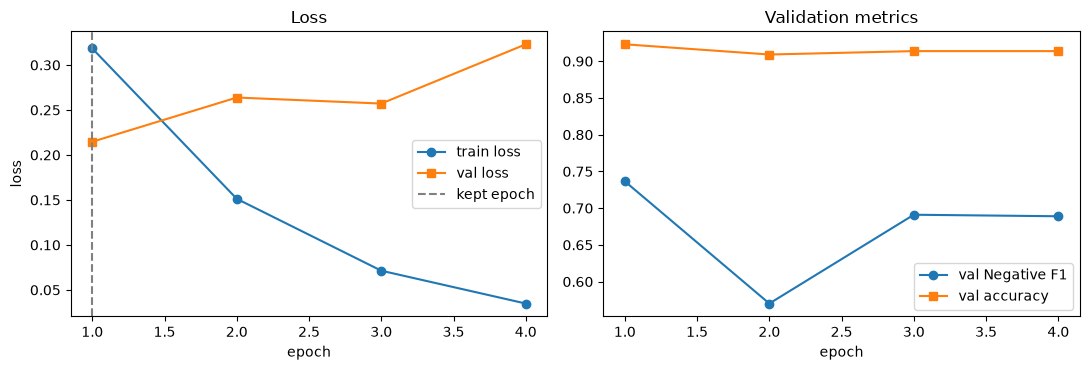

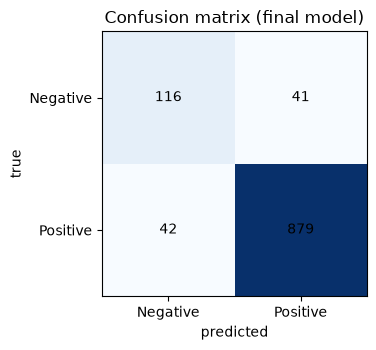

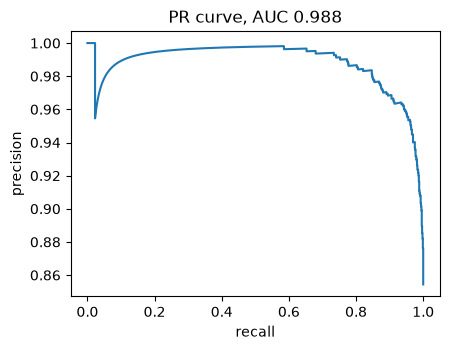

In [9]:
# ==================== PLOTS FOR THE FINAL MODEL (SEED 42) ====================
from sklearn.metrics import confusion_matrix, precision_recall_curve

final42 = finals[0]                                   # the seed-42 run of the final configuration
history = pd.DataFrame(json.loads((RESULTS / "histories" / f"{final42['key']}.json").read_text()))
probs = np.load(RESULTS / "probs" / f"{final42['key']}.npy")
pred = (probs >= 0.5).astype(int)   # decision rule: predict positive when P(positive) >= 0.5
y = np.asarray(val_y)               # true labels of the validation reviews

# Left: loss per epoch. Train loss keeps falling; validation loss turning upward means overfitting. The dashed
# line marks the epoch whose weights were kept by early stopping. Right: validation Negative F1 / accuracy.
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(history["epoch"], history["train_loss"], "o-", label="train loss")
ax[0].plot(history["epoch"], history["val_loss"], "s-", label="val loss")
ax[0].axvline(final42["best_epoch"], color="gray", ls="--", label="kept epoch")
ax[0].set(xlabel="epoch", ylabel="loss", title="Loss"); ax[0].legend()
ax[1].plot(history["epoch"], history["val_neg_f1"], "o-", label="val Negative F1")
ax[1].plot(history["epoch"], history["val_acc"], "s-", label="val accuracy")
ax[1].set(xlabel="epoch", title="Validation metrics"); ax[1].legend()
fig.tight_layout(); fig.savefig(RESULTS / "curves.png", dpi=150); plt.show()

# Confusion matrix: rows = true class, columns = predicted class.
# Example reading: the top-right cell counts negative reviews wrongly called positive (false positives).
cm = confusion_matrix(y, pred, labels=[0, 1])
fig, ax = plt.subplots(figsize=(4.2, 3.6))
ax.imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm):
    ax.text(j, i, int(v), ha="center", va="center")
ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=["Negative", "Positive"], yticklabels=["Negative", "Positive"],
       xlabel="predicted", ylabel="true", title="Confusion matrix (final model)")
fig.tight_layout(); fig.savefig(RESULTS / "confusion.png", dpi=150); plt.show()

# Precision-recall curve for the positive class: sweeps the 0.5 threshold from 0 to 1.
# Area under it (PR-AUC) near 1.0 means positives are ranked well regardless of the exact threshold.
prec, rec, _ = precision_recall_curve(y, probs)
fig, ax = plt.subplots(figsize=(4.6, 3.6))
ax.plot(rec, prec); ax.set(xlabel="recall", ylabel="precision", title=f"PR curve, AUC {final42['pr_auc']:.3f}")
fig.tight_layout(); fig.savefig(RESULTS / "pr_curve.png", dpi=150); plt.show()

In [10]:
# ==================== ERROR ANALYSIS (validation set) ====================
# The test reviews have no labels, so right/wrong analysis uses the validation set. For each error type take the
# 10 mistakes the model was LEAST sure about: the borderline cases are the most useful to discuss. A mistake with
# P(positive)=0.05 on a positive review would be a confident, serious one.
conf = np.abs(probs - 0.5)      # distance from the 0.5 decision boundary: small = unsure
frames = []
for kind, true_label, pred_label in (("false negative (true positive review)", 1, 0),
                                     ("false positive (true negative review)", 0, 1)):
    idx = np.where((y == true_label) & (pred == pred_label))[0]   # validation rows with this error
    idx = idx[np.argsort(conf[idx])][:10]                          # least confident first
    frames.append(pd.DataFrame({
        "error_type": kind, "p_positive": probs[idx].round(3), "true": y[idx],
        "words": [len(val_texts[i].split()) for i in idx], "review": [val_texts[i] for i in idx],
    }))
errors = pd.concat(frames, ignore_index=True)
errors.to_csv(RESULTS / "errors.csv", index=False)   # full text of the 20 examples, for the report
print(f"{(pred != y).sum()} misclassified of {len(y)}; wrote {len(errors)} examples to errors.csv")
# Print 3 of each type. Things to look for: negation ("not bad"), sarcasm, mixed sentiment, long reviews.
for _, r in errors.groupby("error_type").head(3).iterrows():
    print(f"\n[{r.error_type}] p(pos)={r.p_positive} words={r.words}\n{r.review[:300]}")

83 misclassified of 1078; wrote 20 examples to errors.csv

[false negative (true positive review)] p(pos)=0.4970000088214874 words=60
This short is minimalistic. Just what you need if you are doing Yoga. Grips the leg, does not show what you do not what to show. I use black underpants under them, as they are a bit too minimalistic without. I think they are a bit overpriced, but I have not found as good a short for less (low demand

[false negative (true positive review)] p(pos)=0.492000013589859 words=40
These underwear hold up very well and don't rip along the waistband or in the seams. Seven pairs bought in Jan. 2004 lasted over 2 years w/o ripping. The price has not changed since then, either. Definitely worth the money!

[false negative (true positive review)] p(pos)=0.48899999260902405 words=67
I ordered the Brown. The shoes do look better 'in the flesh', and the buckle on the brown is a light bronze colour. They felt like slippers from the start. My only complaint is that the met

In [11]:
# ==================== SANITY CHECKS ====================
# Accuracy of a model that always answers "positive": the bar any real model must clear (about 0.854).
ALWAYS_POSITIVE = max(np.mean(val_y), 1 - np.mean(val_y))
all_runs = pd.DataFrame(RUNS.values())
# Every metric must be a valid proportion; a value outside [0, 1] would mean a bug.
assert all_runs[["accuracy", "neg_f1", "pr_auc"]].apply(lambda c: c.between(0, 1)).all().all()
print(f"always-positive baseline accuracy: {ALWAYS_POSITIVE:.4f}")
print(f"final model (mean of 3 seeds): accuracy {summary['mean']['accuracy']:.4f}, "
      f"Negative F1 {summary['mean']['neg_f1']:.4f}")
if summary["mean"]["accuracy"] <= ALWAYS_POSITIVE:
    print("NOTE: the final model does not beat the always-positive baseline on accuracy; "
          "rely on Negative F1 and PR-AUC when interpreting it.")

always-positive baseline accuracy: 0.8544
final model (mean of 3 seeds): accuracy 0.9208, Negative F1 0.7177


## How to read these numbers (limitations)

- **The validation scores are optimistic.** The same 1,078 validation reviews (only 157 negative) are used to choose the early-stopping epoch, to pick the winner at every stage, and to report the final scores. No unbiased estimate is available here because the test set has no labels.
- **Greedy search.** Stages are tuned in a fixed order and each winner is carried forward, so a combination that only works together (for example a learning rate that is best only for max pooling) can be missed. The order follows expected impact: embeddings and learning rate first.
- **One seed per candidate.** Candidates are compared with seed 42. The noise band (Stage 0, three baseline seeds) says how big a gap must be to count; candidates inside the band are treated as tied and the simpler one wins. With only three seeds the noise estimate itself is rough.
- **Seeds 43 and 44 change only the training seed** (initialisation of the LSTM and classifier, batch order, dropout). The random vectors used for words missing from GloVe always come from seed 42.
- **Fixed, untuned settings:** layers (1), dropout (0.4), batch size (64), bidirectional, `MAX_LEN` (150), GloVe dimension (100), max 15 epochs with patience 3.
- `trainable_params` counts only parameters that are trained, so frozen-embedding runs exclude the 0.7M embedding weights.